# Home credit default risk - Model experiments

## 1.Data preparation

dataset is split into train,val,test datasets   
also saving the names of feature and categorical columns

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split
import sys
from pathlib import Path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.preprocessing import prepare_features
from src.model import make_catboost
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
import json
import optuna
from src.predict import predict
from sklearn.metrics import (
    average_precision_score,
    recall_score,
    precision_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
raw_df = pd.read_csv('../data/application_train.csv')

In [3]:
pd.set_option('display.max_rows', 20)
raw_df
y = raw_df['TARGET']
X = raw_df.drop(columns=['TARGET', 'SK_ID_CURR'])

In [4]:
X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42 , test_size=0.3)
X_val, X_test, y_val, y_test = train_test_split(X_val, y_val, stratify=y_val, random_state=42, test_size=0.5)

In [5]:
feature_columns = X_train.columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object', 'str']).columns.tolist()

## 2.Feature engineering

Preparing features with function from file preprocessing.py
Adding a couple new columns and fixing some that are already exist. Like filling NA etc.

In [6]:
X_train = prepare_features(X_train,feature_columns, categorical_cols)
X_val = prepare_features(X_val, feature_columns, categorical_cols)

## 3.Baseline Models

Creating models for comparassion.
Like default Catboost, dummy, logistic regression

In [7]:
model = CatBoostClassifier(
    iterations=1000,
    learning_rate=0.05,
    loss_function='Logloss',
    verbose=50,
    random_seed=42,
    depth=4,
    auto_class_weights='Balanced'
)


In [8]:
model.fit(X_train, y_train, cat_features=categorical_cols)

0:	learn: 0.6870861	total: 275ms	remaining: 4m 34s
50:	learn: 0.6103649	total: 5.38s	remaining: 1m 40s
100:	learn: 0.5989576	total: 10.5s	remaining: 1m 33s
150:	learn: 0.5935346	total: 15.4s	remaining: 1m 26s
200:	learn: 0.5902781	total: 20.5s	remaining: 1m 21s
250:	learn: 0.5870600	total: 25.5s	remaining: 1m 16s
300:	learn: 0.5835074	total: 30.6s	remaining: 1m 11s
350:	learn: 0.5803529	total: 35.8s	remaining: 1m 6s
400:	learn: 0.5778557	total: 41.1s	remaining: 1m 1s
450:	learn: 0.5756600	total: 46.4s	remaining: 56.4s
500:	learn: 0.5734752	total: 51.5s	remaining: 51.3s
550:	learn: 0.5714702	total: 56.7s	remaining: 46.2s
600:	learn: 0.5696294	total: 1m 1s	remaining: 41.1s
650:	learn: 0.5678762	total: 1m 7s	remaining: 36s
700:	learn: 0.5660823	total: 1m 12s	remaining: 30.9s
750:	learn: 0.5642756	total: 1m 17s	remaining: 25.7s
800:	learn: 0.5626586	total: 1m 23s	remaining: 20.7s
850:	learn: 0.5610273	total: 1m 28s	remaining: 15.5s
900:	learn: 0.5594716	total: 1m 33s	remaining: 10.3s
950:	

CatBoostClassifier(auto_class_weights='Balanced', depth=4, iterations=1000, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=50)

In [9]:
train_proba = model.predict_proba(X_train)[:, 1]
val_proba = model.predict_proba(X_val)[:, 1]

print(
    f'Train roc-auc-score: {roc_auc_score(y_train, train_proba)}\n'
    f'Val roc-auc-score: {roc_auc_score(y_val, val_proba)}'
    )

Train roc-auc-score: 0.7890240962326344
Val roc-auc-score: 0.7611809431334188


In [10]:
from sklearn.metrics import accuracy_score

accuracy_score(y_true=y_val, y_pred=model.predict(X_val))

auc_cb = roc_auc_score(y_val,model.predict_proba(X_val)[:, 1])
recall_cb = recall_score(y_val,model.predict(X_val) )

In [11]:
numeric_cols = X_train.select_dtypes(include='number').columns.tolist()

In [12]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('target_encoder', TargetEncoder(random_state=42))
])

preprocessing = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

final_pipeline =  Pipeline(steps=[
    ('preprocessing', preprocessing),
    ('model',LogisticRegression(
        solver='lbfgs',
        penalty='l2',
        max_iter=500,
        n_jobs=1,
        random_state=42
    ))
])

In [13]:
final_pipeline.fit(X_train, y_train)

c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:1457: FutureWarning: 'n_jo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](123,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',...,'Income_div_credit', 'Price_div_amount','Annuity_div_income']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,123
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``)

In [14]:
logreg_proba = final_pipeline.predict_proba(X_val)[:, 1]
logreg_preds = final_pipeline.predict(X_val)

In [15]:
logreg_auc = roc_auc_score(y_val, logreg_proba)
logreg_recall = recall_score(y_val, logreg_preds)

In [16]:
logreg_recall

0.01100966702470462

In [17]:
dummy_clf = DummyClassifier(strategy='prior')

In [18]:
dummy_clf.fit(X_train, y_train)


,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'prior'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.92,0.08]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](123,)","['NAME_CONTRACT_TYPE','CODE_GENDER','FLAG_OWN_CAR',...,'Income_div_credit', 'Price_div_amount','Annuity_div_income']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,123
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [19]:
dummy_proba = dummy_clf.predict_proba(X_val)[:, 1]
dummy_preds = dummy_clf.predict(X_val)

In [20]:
auc_dummy = roc_auc_score(y_val, dummy_proba)
recall_dummy = recall_score(y_val, dummy_preds)

## 4.Hyperparameter Optimization

Creating optuna study to select best params for catboost (depth, learning_rate, l2_leaf_reg)
Also adding early_stopping to get the best amount of iterations

In [21]:

RUN_OPTUNA = False

if RUN_OPTUNA:
    def objective(trial):
        params = {
            'depth': trial.suggest_int('depth', 4, 8),
            'learning_rate': trial.suggest_float('learning_rate', 0.03, 0.15, log=True),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True)
        }

        model = CatBoostClassifier(
            **params,
            iterations=1000,
            loss_function='Logloss',
            auto_class_weights='Balanced',
            eval_metric='AUC', 
            early_stopping_rounds=50,
            use_best_model=True,
            random_seed=42,
            verbose=False
        )

        model.fit(X_train, y_train,cat_features=categorical_cols, eval_set=(X_val, y_val))

        scores = model.predict_proba(X_val)[:, 1]

        return roc_auc_score(y_val, scores)

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=10)

    

    with open('../artifacts/best_params.json', 'w', encoding='utf-8') as f:
        json.dump(study.best_params, f, indent=4)

In [22]:
with open('../artifacts/best_params.json', 'r', encoding='utf-8') as f:
    best_params = json.load(f)

cb_optuna = make_catboost(**best_params)

In [23]:
cb_optuna.fit(X_train, y_train, cat_features=categorical_cols, eval_set=(X_val,y_val))

0:	test: 0.6968039	best: 0.6968039 (0)	total: 148ms	remaining: 2m 27s
50:	test: 0.7337199	best: 0.7337199 (50)	total: 7.11s	remaining: 2m 12s
100:	test: 0.7424415	best: 0.7424415 (100)	total: 13.9s	remaining: 2m 4s
150:	test: 0.7463680	best: 0.7463680 (150)	total: 20.7s	remaining: 1m 56s
200:	test: 0.7491409	best: 0.7491409 (200)	total: 27.5s	remaining: 1m 49s
250:	test: 0.7509370	best: 0.7509370 (250)	total: 34.2s	remaining: 1m 42s
300:	test: 0.7523363	best: 0.7523363 (300)	total: 40.9s	remaining: 1m 35s
350:	test: 0.7535415	best: 0.7535415 (350)	total: 47.7s	remaining: 1m 28s
400:	test: 0.7553683	best: 0.7553683 (400)	total: 54.5s	remaining: 1m 21s
450:	test: 0.7567981	best: 0.7567981 (450)	total: 1m 1s	remaining: 1m 14s
500:	test: 0.7577975	best: 0.7577975 (500)	total: 1m 8s	remaining: 1m 8s
550:	test: 0.7586924	best: 0.7586924 (550)	total: 1m 16s	remaining: 1m 2s
600:	test: 0.7590810	best: 0.7591055 (599)	total: 1m 23s	remaining: 55.3s
650:	test: 0.7595442	best: 0.7595442 (650)	tot

CatBoostClassifier(auto_class_weights='Balanced', depth=5, early_stopping_rounds=50, eval_metric='AUC', iterations=1000, l2_leaf_reg=4.192399482186271, learning_rate=0.03447179333965802, loss_function='Logloss', random_seed=42, use_best_model=True, verbose=50)

In [24]:
bm_cb_proba = cb_optuna.predict_proba(X_val)[:, 1]
bm_cb_preds = cb_optuna.predict(X_val)

bm_cb_auc = roc_auc_score(y_val, bm_cb_proba)
bm_cb_recall = recall_score(y_val, bm_cb_preds)

## 5.Model comparasion

Comparing basic models with the best catboost one (from optuna study)
Comparing metrics like : roc_auc_score and recall(the most important for us)

In [25]:
model_comp = pd.DataFrame({
    'model': ['catboost' , 'logreg', 'dummy', 'catboost_optuna'],
    'roc_auc_score': [auc_cb, logreg_auc, auc_dummy,bm_cb_auc],
    'recall (threshold = 0.5)': [recall_cb, logreg_recall, recall_dummy, bm_cb_recall]
})

In [26]:
model_comp

,model,roc_auc_score,recall (threshold = 0.5)
0,catboost,0.761181,0.670784
1,logreg,0.745312,0.011010
2,dummy,0.500000,0.000000
3,catboost_optuna,0.761554,0.667562


## 6. Decision Threshold Selection

Tryna get the best threshold as possible
The main goal is to have the best recall with normal precision
Because in this case FN are the ones that need to be cheched the most

In [27]:
threshold = 0.35


rows = []

while(threshold <= 0.66):
    results = pd.DataFrame({
    'actual': y_val.to_numpy(),
    'risk_scores': bm_cb_proba
    })

    results['prediction'] = (results['risk_scores'] >= threshold).astype(int)
    results['match'] = (results['prediction'] == results ['actual']).astype(int)

    results['distance'] = abs(results[results['prediction'] == 0]['risk_scores'] - threshold)

    n_review = int(np.ceil(len(results) * 0.10))

    review_idx = results.nsmallest(n_review, 'distance').index

    results['need_review'] = False
    results.loc[review_idx, 'need_review'] = True

    results = results.drop(columns='distance')

    TP = ((results['match'] == 1) & (results['prediction'] == 1)).sum()
    FP = ((results['match'] == 0) & (results['prediction'] == 1)).sum()
    FN = ((results['match'] == 0) & (results['prediction'] == 0)).sum()

    precision_ovr = (TP / (TP + FP)) * 100
    recall_ovr = (TP / (TP + FN)) * 100

    results_check = results[results['need_review'] == True]

    FP_check = ((results_check['match'] == 0) & (results_check['prediction'] == 1)).sum()
    FN_check = ((results_check['match'] == 0) & (results_check['prediction'] == 0)).sum()

    ##Result
    rows.append({
    'threshold': round(threshold, 2),
    'precision_pct': precision_ovr,
    'recall_pct': recall_ovr,
    'FN_all': FN,
    'FN_review': FN_check,
    'FN_diff' : FN - FN_check,
    'FP_all': FP,
    'F1_pct': 2 * (precision_ovr * recall_ovr) / (precision_ovr + recall_ovr)
    })

    threshold += 0.01


In [28]:
pd.set_option('display.max_rows', 50)

pd.DataFrame(rows)

,threshold,precision_pct,recall_pct,FN_all,FN_review,FN_diff,FP_all,F1_pct
0,0.35,12.603889,86.331901,509,192,317,22293,21.996442
1,0.36,12.853907,85.338346,546,195,351,21546,22.342520
2,0.37,13.156355,84.505908,577,195,382,20773,22.768051
3,0.38,13.359274,82.975295,634,228,406,20040,23.013331
4,0.39,13.628239,81.901182,674,227,447,19330,23.368066
5,0.40,13.949401,80.988185,708,231,477,18605,23.799566
6,0.41,14.246051,79.914071,748,239,509,17914,24.181360
7,0.42,14.535172,78.678840,794,250,544,17228,24.537308
8,0.43,14.830247,77.416756,841,271,570,16557,24.892074
9,0.44,15.102302,75.912997,897,281,616,15892,25.192710


## 7. Final Test Evaluation

Doing some basic metrics on test datasets with the best model we have

In [29]:
X_test = prepare_features(X_test, feature_columns, categorical_cols)

In [30]:

test_proba = cb_optuna.predict_proba(X_test)[:, 1]
test_preds = (test_proba >= 0.40).astype(int)

test_metrics = {
    'roc_auc': roc_auc_score(y_test, test_proba),
    'average_precision': average_precision_score(y_test, test_proba),
    'recall': recall_score(y_test, test_preds),
    'precision': precision_score(y_test, test_preds),
    'f1': f1_score(y_test, test_preds)
}

display(pd.DataFrame([test_metrics]).round(4))

,roc_auc,average_precision,recall,precision,f1
0,0.7642,0.2484,0.8096,0.1403,0.2391


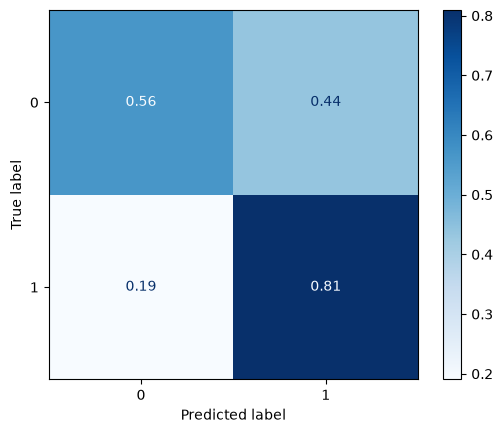

In [31]:
cm = confusion_matrix(y_test, test_preds, normalize='true')

ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap='Blues')
plt.show()

In [32]:
schema = {
    'feature_columns': feature_columns,
    'categorical_columns': categorical_cols,
    'threshold' : 0.40
}

## 8. Manual Review Strategy

The final act of my code.
The logic is that: There is not enough human resources to check everyone. So from all the result that our model
has given us we are marking as 'need_review' only 10%. An only those who might be FN and have the highest chances of being it

In [33]:
predict_df = raw_df.loc[y_test.index]

predictions = predict(predict_df,cb_optuna,schema)

In [34]:
predictions

,SK_ID_CURR,risk_scores,predictions,need_review
17987,232843,0.965921,1,False
39910,395476,0.959908,1,False
39801,444695,0.958735,1,False
31806,168260,0.957912,1,False
4319,427557,0.955402,1,False
...,...,...,...,...
24268,249554,0.020870,0,False
3431,100889,0.019122,0,False
40942,406032,0.017797,0,False
44244,177745,0.011877,0,False


In [35]:
results = predictions.merge(predict_df[['SK_ID_CURR', 'TARGET']],on='SK_ID_CURR' ,how='left')

In [36]:
fn_idx  = results[(results['predictions'] == 0) & (results['TARGET'] == 1)].index
FN = len(fn_idx)
FN_check = results.loc[fn_idx,'need_review'].sum()
FN_not_checked = FN - FN_check



In [37]:
print(f'FN: {FN}')
print(f'Sent for check FN: {FN_check}')
print(f'Not sent for check: {FN_not_checked}')
print(f'% of being sent for check= {(FN_check/FN) * 100}%')

FN: 709
Sent for check FN: 224
Not sent for check: 485
% of being sent for check= 31.59379407616361%


In [38]:
CREATE_SAMPLE  = False

if CREATE_SAMPLE:
    sample = (
        raw_df.sample(n = 50, random_state=42)
        .drop(columns='TARGET')
    )
    sample.to_csv('../data/sample_inputs.csv', index=False)

## 9.Conclusion

At the end from our inputs we are getting 10% of overall amount for manual check, approximately 31.5% of
FN are being marked as 'need_review'. And is that having 80%+ of recall
ROC-AUC — 0.7642.
Recall — 80.96%.
Precision — 14.03%.
Manual review finds 224 of 709 missed defaults (31.59%).